# Data Cleaning — Titanic Passenger Dataset
### OIBSIP Data Analytics Internship — Level 1, Task 3

**Author:** Vineet Pandey

**Objective:** Take a real-world dataset with missing values, outliers and inconsistent formats and turn it into a
clean, analysis-ready dataset, documenting every decision along the way.

**Dataset:** Titanic passenger data (891 passengers, 12 columns). It is one of the datasets suggested in the task guidelines.

**Cleaning plan:**
1. Data quality report (what is wrong?)
2. Handle missing data
3. Remove duplicates
4. Standardise formats
5. Detect and handle outliers
6. Correct data types
7. Before vs after summary, then save the cleaned CSV


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)


## 1. Load Data & Data Quality Report

In [2]:
df = pd.read_csv("titanic.csv")
df_raw = df.copy()          # keep an untouched copy for the before/after comparison
print("Shape:", df.shape)
df.head()


Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Column meanings:** `Survived` (0 = no, 1 = yes), `Pclass` (ticket class 1/2/3), `SibSp`/`Parch` (siblings-spouses and
parents-children aboard), `Fare` (ticket price), `Cabin` (cabin number), `Embarked` (port: C, Q or S).

In [3]:
# --- Data quality report ---
quality = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Null_Count': df.isnull().sum(),
    'Null_%': (df.isnull().mean() * 100).round(1),
    'Unique_Values': df.nunique()
})
quality


,Data_Type,Null_Count,Null_%,Unique_Values
PassengerId,int64,0,0.0,891
Survived,int64,0,0.0,2
Pclass,int64,0,0.0,3
Name,str,0,0.0,891
Sex,str,0,0.0,2
Age,float64,177,19.9,88
SibSp,int64,0,0.0,7
Parch,int64,0,0.0,7
Ticket,str,0,0.0,681
Fare,float64,0,0.0,248


In [4]:
print("Duplicate rows (all columns identical):", df.duplicated().sum())
print("Duplicate PassengerId values           :", df['PassengerId'].duplicated().sum())
print()
print("--- Value range checks ---")
print("Fares equal to 0     :", (df['Fare'] == 0).sum())
print("Youngest / oldest age:", df['Age'].min(), "/", df['Age'].max())
print("Ages below 1 year    :", (df['Age'] < 1).sum())
print("Max SibSp / Parch    :", df['SibSp'].max(), "/", df['Parch'].max())
print("Unique Sex values    :", df['Sex'].unique().tolist())
print("Unique Embarked codes:", df['Embarked'].unique().tolist())


Duplicate rows (all columns identical): 0
Duplicate PassengerId values           : 0

--- Value range checks ---
Fares equal to 0     : 15
Youngest / oldest age: 0.42 / 80.0
Ages below 1 year    : 7
Max SibSp / Parch    : 8 / 6
Unique Sex values    : ['male', 'female']
Unique Embarked codes: ['S', 'C', 'Q', nan]


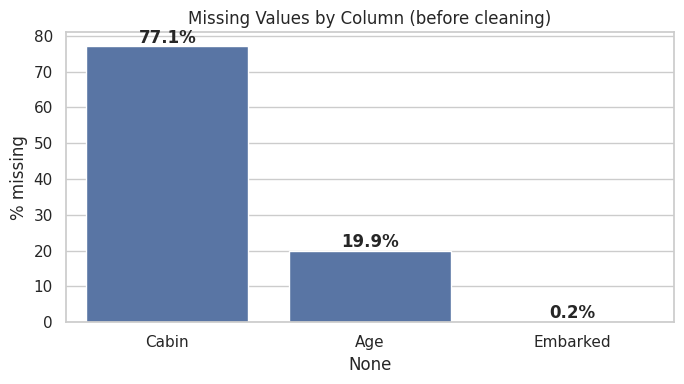

In [5]:
missing = (df.isnull().mean() * 100).round(1)
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(7, 4))
sns.barplot(x=missing.index, y=missing.values, color="#4C72B0")
for i, v in enumerate(missing.values):
    plt.text(i, v + 1, f"{v}%", ha='center', fontweight='bold')
plt.title("Missing Values by Column (before cleaning)")
plt.ylabel("% missing")
plt.tight_layout()
plt.show()


**Data quality findings:**
- **Age** is missing for 177 passengers (about 20%).
- **Cabin** is missing for 687 passengers (about 77%).
- **Embarked** is missing for just 2 passengers.
- There are **no fully duplicate rows**.
- 15 passengers have a **Fare of 0**, which looks unusual, and Fare has some extreme high values.
- `PassengerId` is stored as a number, but it is only a label, and `Pclass` and `Sex` are really categories.

## 2. Handle Missing Data

Each column gets its own strategy, with the reason:

| Column | Missing | Strategy | Why |
|---|---|---|---|
| **Age** | 177 (20%) | Fill with the **median age of the passenger's Pclass and Sex group** | Too many rows to delete. The median is not affected by extreme ages, and using the group median is more realistic than one number for everyone. |
| **Embarked** | 2 | Fill with the **mode** (most common port) | Only 2 rows, and a category column has no average, so the most frequent value is the safest fill. |
| **Cabin** | 687 (77%) | **Drop the column**, but first keep a `Has_Cabin` flag (1/0) | With over three quarters missing, filling would be mostly guesswork. The flag keeps the useful part: whether a cabin was recorded. |

In [6]:
# --- Age: median of the passenger's (Pclass, Sex) group ---
print("Median age by Pclass and Sex:")
print(df.groupby(['Pclass', 'Sex'])['Age'].median())

df['Age'] = df['Age'].fillna(df.groupby(['Pclass', 'Sex'])['Age'].transform('median'))

# --- Embarked: most common value ---
most_common_port = df['Embarked'].mode()[0]
print("\nMost common Embarked code:", most_common_port)
df['Embarked'] = df['Embarked'].fillna(most_common_port)

# --- Cabin: keep a 1/0 flag, then drop the column ---
df['Has_Cabin'] = df['Cabin'].notnull().astype(int)
print("\nPassengers with a cabin recorded, by class:")
print(pd.crosstab(df['Pclass'], df['Has_Cabin']))
df = df.drop(columns=['Cabin'])

print("\nRemaining nulls:", df.isnull().sum().sum())


Median age by Pclass and Sex:
Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Age, dtype: float64

Most common Embarked code: S

Passengers with a cabin recorded, by class:
Has_Cabin    0    1
Pclass             
1           40  176
2          168   16
3          479   12

Remaining nulls: 0


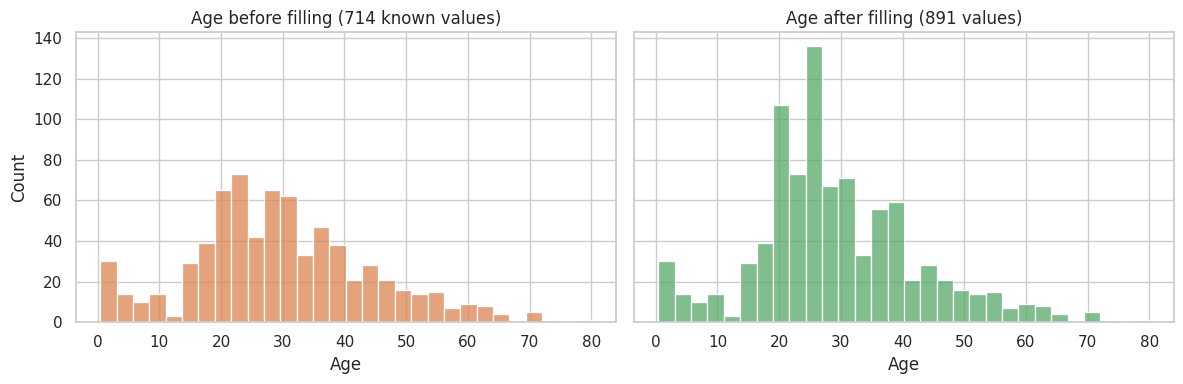

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.histplot(df_raw['Age'].dropna(), bins=30, ax=axes[0], color="#DD8452")
axes[0].set_title("Age before filling (714 known values)")
sns.histplot(df['Age'], bins=30, ax=axes[1], color="#55A868")
axes[1].set_title("Age after filling (891 values)")
plt.tight_layout()
plt.show()


**Observation:** After filling, the overall shape of the Age distribution is preserved, with a taller bar in the
middle because the filled values are group medians. Cabins were recorded far more often for first-class passengers
than for third-class passengers (see the table above), so `Has_Cabin` is a useful feature on its own. No nulls remain.

## 3. Remove Duplicates

In [8]:
before = len(df)
df = df.drop_duplicates()
after = len(df)
print(f"Rows before: {before} | Rows after: {after} | Duplicates removed: {before - after}")

print("\nTickets that appear more than once:", df['Ticket'].duplicated().sum())
df[df['Ticket'] == df['Ticket'].value_counts().index[0]][['Name', 'Ticket', 'Fare']].head()


Rows before: 891 | Rows after: 891 | Duplicates removed: 0

Tickets that appear more than once: 210


,Name,Ticket,Fare
13,"Andersson, Mr. Anders Johan",347082,31.275
119,"Andersson, Miss. Ellis Anna Maria",347082,31.275
541,"Andersson, Miss. Ingeborg Constanzia",347082,31.275
542,"Andersson, Miss. Sigrid Elisabeth",347082,31.275
610,"Andersson, Mrs. Anders Johan (Alfrida Konstant...",347082,31.275


**Decision:** The duplicate check found **0 duplicate rows**, so nothing was removed (the check is still documented
above). Some `Ticket` values do repeat, but those are families or groups travelling on one ticket, not data-entry
errors, so those rows are **kept**.

## 4. Standardise Formats

In [9]:
# 1) Remove stray spaces in text columns
for col in ['Name', 'Sex', 'Ticket', 'Embarked']:
    df[col] = df[col].str.strip()

# 2) Sex: 'male' / 'female' -> 'Male' / 'Female'
df['Sex'] = df['Sex'].str.title()

# 3) Embarked: port codes -> full port names
port_map = {'C': 'Cherbourg', 'Q': 'Queenstown', 'S': 'Southampton'}
df['Embarked'] = df['Embarked'].map(port_map)

# 4) Title from Name (Mr, Mrs, Miss ...) and tidy up variants
df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.', expand=False).str.strip()
print("Titles before tidying:\n", df['Title'].value_counts().to_dict())

df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})   # same meaning, different spelling
common_titles = ['Mr', 'Mrs', 'Miss', 'Master']
df['Title'] = df['Title'].where(df['Title'].isin(common_titles), 'Rare')          # all other uncommon titles
print("\nTitles after tidying:\n", df['Title'].value_counts().to_dict())

df[['Name', 'Sex', 'Embarked', 'Title']].head()


Titles before tidying:
 {'Mr': 517, 'Miss': 182, 'Mrs': 125, 'Master': 40, 'Dr': 7, 'Rev': 6, 'Major': 2, 'Mlle': 2, 'Col': 2, 'Don': 1, 'Mme': 1, 'Ms': 1, 'Lady': 1, 'Sir': 1, 'Capt': 1, 'the Countess': 1, 'Jonkheer': 1}

Titles after tidying:
 {'Mr': 517, 'Miss': 185, 'Mrs': 126, 'Master': 40, 'Rare': 23}


,Name,Sex,Embarked,Title
0,"Braund, Mr. Owen Harris",Male,Southampton,Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Female,Cherbourg,Mrs
2,"Heikkinen, Miss. Laina",Female,Southampton,Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Female,Southampton,Mrs
4,"Allen, Mr. William Henry",Male,Southampton,Mr


**What was standardised:**
- Removed leading and trailing spaces in all text columns.
- `Sex` is now `Male` / `Female` (consistent capitalisation).
- `Embarked` codes (C, Q, S) are now readable port names.
- A new `Title` column was extracted from `Name`. Variants such as *Mlle*, *Ms* (-> Miss) and *Mme* (-> Mrs) were
  merged, and all uncommon titles were grouped into *Rare*.
- There was no date column in this dataset, so no date reformatting was needed.

## 5. Outlier Detection (IQR Method)

**IQR rule:** a value is an outlier if it is below `Q1 - 1.5 x IQR` or above `Q3 + 1.5 x IQR`, where Q1 and Q3
are the 25th and 75th percentiles and IQR = Q3 - Q1.

In [10]:
def iqr_bounds(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in ['Age', 'Fare']:
    low, high = iqr_bounds(df[col])
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append({'Column': col, 'Lower_Bound': round(low, 2), 'Upper_Bound': round(high, 2),
                 'Outliers': n_out, 'Outlier_%': round(n_out / len(df) * 100, 1)})
outlier_report = pd.DataFrame(rows)
outlier_report


,Column,Lower_Bound,Upper_Bound,Outliers,Outlier_%
0,Age,-0.25,57.75,33,3.7
1,Fare,-26.72,65.63,116,13.0


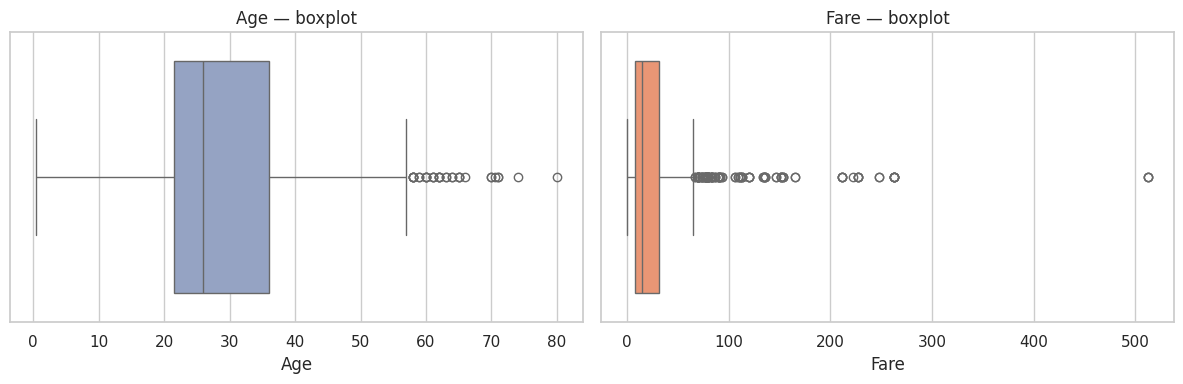

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['Age'], ax=axes[0], color="#8DA0CB")
axes[0].set_title("Age — boxplot")
sns.boxplot(x=df['Fare'], ax=axes[1], color="#FC8D62")
axes[1].set_title("Fare — boxplot")
plt.tight_layout()
plt.show()


**Decisions:**

| Column | Decision | Reason |
|---|---|---|
| **Age** | **Retain** | Every value is a realistic age (the oldest passenger is 80). These are real elderly passengers, not errors. |
| **Fare** | **Cap** at the upper IQR bound in a **new column** `Fare_Capped`, and keep the original `Fare` | Very expensive first-class tickets are real, but a few extreme fares can distort averages. Capping reduces that effect without deleting any passenger. |
| **Fare = 0** | **Retain** and flag with `Zero_Fare` | We cannot tell if these were free tickets, crew, or recording errors, so we flag instead of guessing a value. |

In [12]:
low, high = iqr_bounds(df['Fare'])
df['Fare_Capped'] = df['Fare'].clip(upper=high)
df['Zero_Fare'] = (df['Fare'] == 0).astype(int)

print(f"Fare upper bound used for capping: {high:.2f}")
print("Max Fare before capping :", round(df['Fare'].max(), 2))
print("Max Fare after capping  :", round(df['Fare_Capped'].max(), 2))
print("Mean Fare before / after:", round(df['Fare'].mean(), 2), "/", round(df['Fare_Capped'].mean(), 2))
print("Rows with Zero_Fare flag:", df['Zero_Fare'].sum())


Fare upper bound used for capping: 65.63
Max Fare before capping : 512.33
Max Fare after capping  : 65.63
Mean Fare before / after: 32.2 / 24.05
Rows with Zero_Fare flag: 15


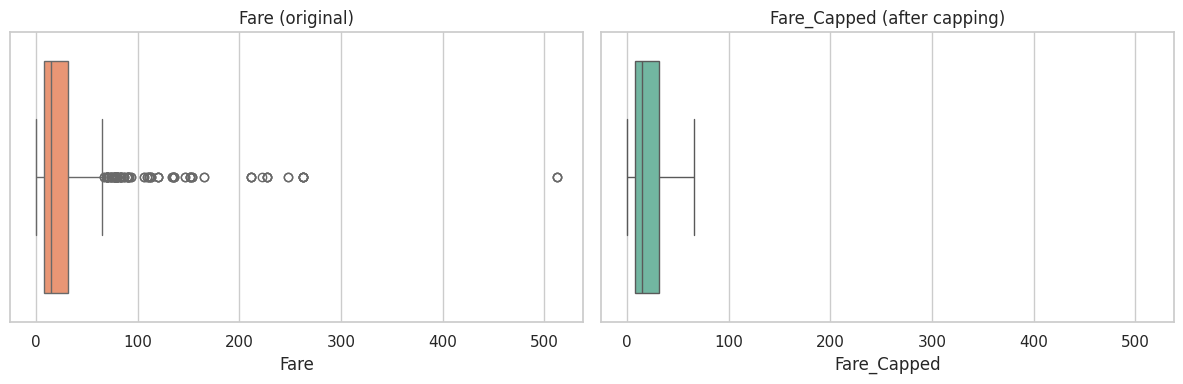

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
sns.boxplot(x=df['Fare'], ax=axes[0], color="#FC8D62")
axes[0].set_title("Fare (original)")
sns.boxplot(x=df['Fare_Capped'], ax=axes[1], color="#66C2A5")
axes[1].set_title("Fare_Capped (after capping)")
plt.tight_layout()
plt.show()


## 6. Correct Data Types

| Column | Correct type | Why |
|---|---|---|
| `PassengerId` | string | It is an ID label, and we never do maths on it |
| `Pclass`, `Sex`, `Embarked`, `Title` | category | A small set of fixed groups |
| `Survived`, `Has_Cabin`, `Zero_Fare` | integer (0/1) | Yes/no flags used in calculations |
| `Age`, `Fare`, `Fare_Capped` | float | Can have decimals |
| `Name`, `Ticket` | string | Free text |

In [14]:
df['PassengerId'] = df['PassengerId'].astype(str)
for col in ['Pclass', 'Sex', 'Embarked', 'Title']:
    df[col] = df[col].astype('category')

df.dtypes


PassengerId         str
Survived          int64
Pclass         category
Name                str
Sex            category
Age             float64
SibSp             int64
Parch             int64
Ticket              str
Fare            float64
Embarked       category
Has_Cabin         int64
Title          category
Fare_Capped     float64
Zero_Fare         int64
dtype: object

## 7. Before vs After Summary

In [15]:
expected = {
    'PassengerId': 'string', 'Survived': 'int', 'Pclass': 'category', 'Name': 'string',
    'Sex': 'category', 'Age': 'float', 'SibSp': 'int', 'Parch': 'int', 'Ticket': 'string',
    'Fare': 'float', 'Cabin': 'string', 'Embarked': 'category',
    'Has_Cabin': 'int', 'Title': 'category', 'Fare_Capped': 'float', 'Zero_Fare': 'int'
}

def type_ok(series, kind):
    if kind == 'category': return isinstance(series.dtype, pd.CategoricalDtype)
    if kind == 'int':      return pd.api.types.is_integer_dtype(series)
    if kind == 'float':    return pd.api.types.is_float_dtype(series)
    if kind == 'string':   return pd.api.types.is_string_dtype(series) and not isinstance(series.dtype, pd.CategoricalDtype)

def correct_types(frame):
    ok = sum(type_ok(frame[c], expected[c]) for c in frame.columns)
    return f"{ok} / {len(frame.columns)}"

summary = pd.DataFrame({
    'Before cleaning': [len(df_raw), df_raw.shape[1], int(df_raw.isnull().sum().sum()),
                        int((df_raw.isnull().sum() > 0).sum()), int(df_raw.duplicated().sum()), correct_types(df_raw)],
    'After cleaning':  [len(df), df.shape[1], int(df.isnull().sum().sum()),
                        int((df.isnull().sum() > 0).sum()), int(df.duplicated().sum()), correct_types(df)]
}, index=['Rows', 'Columns', 'Total null values', 'Columns with nulls', 'Duplicate rows', 'Columns with correct dtype'])
summary


,Before cleaning,After cleaning
Rows,891,891
Columns,12,15
Total null values,866,0
Columns with nulls,3,0
Duplicate rows,0,0
Columns with correct dtype,8 / 12,15 / 15


**Observation:** Total null values fall from 866 to 0, and every column now has the correct data type. The row count stays
at 891 because no duplicates were found, and no passenger was deleted. The column count changes because `Cabin` was dropped
and four useful columns were added: `Has_Cabin`, `Title`, `Fare_Capped` and `Zero_Fare`.

## 8. Save the Cleaned Dataset

In [16]:
df.to_csv("titanic_cleaned.csv", index=False)
check = pd.read_csv("titanic_cleaned.csv")
print("Saved titanic_cleaned.csv ->", check.shape[0], "rows,", check.shape[1], "columns")
print("Nulls in saved file:", check.isnull().sum().sum())
check.head()


Saved titanic_cleaned.csv -> 891 rows, 15 columns
Nulls in saved file: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Has_Cabin,Title,Fare_Capped,Zero_Fare
0,1,0,3,"Braund, Mr. Owen Harris",Male,22.0,1,0,A/5 21171,7.2500,Southampton,0,Mr,7.2500,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Female,38.0,1,0,PC 17599,71.2833,Cherbourg,1,Mrs,65.6344,0
2,3,1,3,"Heikkinen, Miss. Laina",Female,26.0,0,0,STON/O2. 3101282,7.9250,Southampton,0,Miss,7.9250,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Female,35.0,1,0,113803,53.1000,Southampton,1,Mrs,53.1000,0
4,5,0,3,"Allen, Mr. William Henry",Male,35.0,0,0,373450,8.0500,Southampton,0,Mr,8.0500,0


## 9. Conclusion

The Titanic data is now analysis-ready. The main steps and decisions were:

1. **Missing data:** Age filled with the group median, Embarked with the mode, and Cabin dropped after keeping a `Has_Cabin` flag.
2. **Duplicates:** none found, so no rows were removed.
3. **Standardised formats:** consistent text, readable port names, and a clean `Title` column.
4. **Outliers:** Age retained as genuine values, Fare capped into a separate column, zero fares flagged.
5. **Data types:** IDs as text, groups as categories, flags as integers.

The original raw data is kept in `titanic.csv` and the cleaned version is saved as `titanic_cleaned.csv`, so every
change can be traced and reversed.
